# B4 · Does task relevance improve transfer?
Compare a text-only DeBERTa control, a paired cross-encoder, the same pair with explicit relevance, and a BIPIA-only training ablation. The full experiment runs each configuration with three seeds.

**First run.** Choose a GPU under **Runtime → Change runtime type**. Have the accompanying `b4-colab-source.zip` ready for the first upload. The notebook saves it and the experiment outputs under your Google Drive. For DVC data access, add your team's read-only R2 keys to Colab Secrets under `R2_ACCESS_KEY_ID` and `R2_SECRET_ACCESS_KEY`. The upload data mode below works with an already-prepared local dataset and context sidecar.

Start with **smoke** and run all cells. Then change the mode to **full** and run all again. To run the optional learning-rate search, set `INCLUDE_SWEEP = True` before running full. Keep enough Drive space for twelve saved models and the active checkpoint. Use a new study name when changing source or configuration.

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
MODE = "full"  # @param ["smoke", "full", "sweep"]
DATA_MODE = "upload"  # @param ["dvc", "upload"]
DRIVE_PROJECT = "/content/drive/MyDrive/CS7267-LLM-Injection-Defense"  # @param {type:"string"}
INCLUDE_SWEEP = False  # @param {type:"boolean"}
STUDY = "b4-relevance-v1"  # @param {type:"string"}

## Set up the experiment
If you uploaded the project folders to Drive, select `upload` and set `DRIVE_PROJECT` to the absolute Colab path of the folder containing `dist` (for example, `/content/drive/MyDrive/CS7267-LLM-Injection-Defense`). The notebook reads the prepared files under `dist/cs7267-b4/<STUDY>`, which `python scripts/package_b4_colab.py --inputs --study <STUDY>` creates locally. Leave the field blank to use the study folder or upload chooser. After a disconnect, use the same study name.

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import os
import re
import shutil
import subprocess
import sys
from google.colab import drive, files

assert re.fullmatch(r"[A-Za-z0-9_-]+", STUDY), "Use a simple study folder name."
drive.mount("/content/drive", force_remount=True)
ROOT = Path("/content/drive/MyDrive/cs7267-b4") / STUDY
ROOT.mkdir(parents=True, exist_ok=True)
WORK = Path("/content/b4-work") / STUDY
WORK.mkdir(parents=True, exist_ok=True)
INPUT_ROOT = ROOT
if DRIVE_PROJECT.strip():
    INPUT_ROOT = Path(DRIVE_PROJECT.strip()) / 'dist/cs7267-b4' / STUDY
    if DATA_MODE != 'upload':
        raise ValueError('DRIVE_PROJECT reads prepared inputs: select upload mode, or clear DRIVE_PROJECT to use DVC.')
    if not (INPUT_ROOT / 'b4-colab-source.zip').is_file():
        raise ValueError(f'No b4-colab-source.zip in {INPUT_ROOT}. Run python scripts/package_b4_colab.py --inputs --study {STUDY} and upload dist.')
archive = INPUT_ROOT / "b4-colab-source.zip"
if not archive.is_file():
    print("Upload b4-colab-source.zip")
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Select the single B4 code archive.")
    archive.write_bytes(next(iter(uploaded.values())))
    del uploaded
with ZipFile(archive) as source:
    for entry in source.namelist():
        if not (WORK / entry).resolve().is_relative_to(WORK.resolve()):
            raise ValueError("Unexpected archive path")
    if "src/models/b4_experiments.py" not in source.namelist():
        raise ValueError("Expected the code archive made by package_b4_colab.py")
    source.extractall(WORK)
os.chdir(WORK)
env = {**os.environ, "PYTHONPATH": os.pathsep.join(str(WORK / p) for p in ["src/data", "src/eval", "src/models"])}
def run(*args, custom_env=None):
    subprocess.run([str(x) for x in args], cwd=WORK, env=env if custom_env is None else custom_env, check=True)

if not shutil.which("uv"):
    run(sys.executable, "-m", "pip", "install", "-q", "uv")
if not (WORK / ".git").exists():
    run("git", "init", "-q")
run("uv", "sync", "--python", "3.11", "--frozen", "--group", "deberta", "--group", "dev")
PY = WORK / ".venv/bin/python"
run(PY, "-c", "import torch; assert torch.cuda.is_available(), 'Select a GPU runtime'; print(torch.cuda.get_device_name(0))")
print("Study folder", ROOT)

Mounted at /content/drive
Study folder /content/drive/MyDrive/cs7267-b4/b4-relevance-v1


## Prepare the paired data
The notebook joins original row IDs to independently supplied questions or task catalogues. For the upload option, select all three local files together: `dataset.parquet`, `contexts.parquet` and `contexts.coverage.csv`. For DVC, credentials go only to the download process.

In [ ]:
import pandas as pd
DATA = WORK / "data/processed/dataset.parquet"
CTX = INPUT_ROOT / "inputs/contexts.parquet"
COVERAGE = CTX.with_suffix(".coverage.csv")
CTX.parent.mkdir(parents=True, exist_ok=True)
if DATA_MODE == "dvc":
    from google.colab import userdata
    targets = ["data/processed/dataset.parquet"]
    if not CTX.exists() or not COVERAGE.exists():
        targets.extend(["data/raw", "data/generated/bipia/qa", "data/generated/bipia/abstract"])
    if not DATA.exists() or len(targets) > 1:
        run(WORK / ".venv/bin/dvc", "pull", *targets, custom_env={
            **env, "AWS_ACCESS_KEY_ID": userdata.get("R2_ACCESS_KEY_ID"),
            "AWS_SECRET_ACCESS_KEY": userdata.get("R2_SECRET_ACCESS_KEY")})
    if not CTX.exists() or not COVERAGE.exists():
        run(PY, "src/data/b4_data.py", "--data", DATA, "--out", CTX)
else:
    DATA = INPUT_ROOT / "inputs/dataset.parquet"
    required = [DATA, CTX, COVERAGE]
    if not all(p.is_file() for p in required):
        received = files.upload()
        for p in required:
            if p.name in received:
                p.write_bytes(received[p.name])
        del received
    if not all(p.is_file() for p in required):
        raise ValueError("Expected dataset.parquet, contexts.parquet and contexts.coverage.csv")
coverage = pd.read_csv(COVERAGE)
display(coverage.groupby(["source", "label"])[["total", "supported", "excluded"]].sum())

total  supported  excluded
source      label                            
bipia       0       2806       2806         0
            1       2806       2806         0
mcptox      0        362        269        93
            1        485        403        82
msb         0         21         21         0
            1         70         55        15
poisonedrag 0       2955       2955         0
            1       1500       1500         0

## Run the experiments
**Smoke** trains one small run and scores validation. **Sweep** compares two learning rates on validation. **Full** trains the 12 reported runs, then scores the familiar test split and the supported MCPTox and MSB rows. A full run repeats the sweep automatically if enabled, reusing finished training. Each epoch is checkpointed while its run is active. Model, score, and report files are written to Drive.

In [ ]:
import json
# Use the project interpreter for YAML and all experiment code.
cfg = ROOT / "b4.yaml"
run(PY, "-c", """import sys,yaml
from pathlib import Path
c=yaml.safe_load(Path('configs/b4.yaml').read_text())
c['search']['enabled']=sys.argv[2]=='True'
Path(sys.argv[1]).write_text(yaml.safe_dump(c, sort_keys=False))
""", cfg, str(INCLUDE_SWEEP))
OUT = ROOT / ("experiments-sweep" if INCLUDE_SWEEP else "experiments-fixed")
command = [PY, "-u", "src/models/b4_experiments.py", "--config", cfg, "--out", OUT,
           "--mode", MODE, "--data", DATA, "--contexts", CTX, "--device", "cuda"]
print(f"Starting {MODE} mode. Progress folder: {OUT}", flush=True)
with subprocess.Popen(command, cwd=WORK, env={**env, "MPLBACKEND": "Agg"},
                      stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, errors="replace") as process:
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        if process.wait() != 0:
            raise subprocess.CalledProcessError(process.returncode, command)
    except KeyboardInterrupt:
        process.terminate()
        raise
print("Outputs", OUT)

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

R = Path("/content/drive/MyDrive/cs7267-b4/b4-relevance-v1/experiments-fixed/reports")
scores = pd.read_csv(R / "seed_summary.csv").query("slice == 'all' and metric == 'auroc'")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, name in zip(axes, ["test", "mcptox", "msb"]):
    part = scores[scores.eval_set == name]
    ax.bar(part.experiment, part["mean"], yerr=part["std"].fillna(0), capsize=3)
    ax.axhline(0.5, color="gray", linestyle="--")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)

axes[0].set_ylabel("AUROC (mean ± seed SD)")
fig.tight_layout()
fig.savefig(R / "auroc.png", dpi=160)
plt.close(fig)

## Inspect results
The feature comparison is `pair_only → relevance` at the same seed. Positive AUROC or matched-5%-FPR detection differences indicate improvement for that seed. The two tool benchmarks use server task catalogues as a proxy for the runtime request. Report coverage alongside their scores.

# B4 relevance experiments

All comparisons use the supported-context cohort.
Schema agreement is deferred. Context catalogues are not observed runtime requests.
Seed intervals are 95% t-intervals over independent seeds (not clipped to [0,1]).
Per-run CSVs also contain bootstrap intervals from the shared harness.

Configuration selected on validation only: **relevance**.

| Experiment | Eval set | AUROC mean | Seed SD | 95% seed CI |
|---|---|---:|---:|---|
| pair_only | mcptox | 0.5056 | 0.0122 | [0.4754, 0.5359] |
| pair_only | msb | 0.3348 | 0.1512 | [-0.0409, 0.7105] |
| pair_only | test | 0.9910 | 0.0017 | [0.9869, 0.9952] |
| relevance | mcptox | 0.4536 | 0.0989 | [0.2079, 0.6993] |
| relevance | msb | 0.2573 | 0.0837 | [0.0495, 0.4651] |
| relevance | test | 0.9900 | 0.0018 | [0.9856, 0.9944] |
| relevance_bipia | mcptox | 0.3973 | 0.0614 | [0.2448, 0.5498] |
| relevance_bipia | msb | 0.1750 | 0.0651 | [0.0134, 0.3367] |
| relevance_bipia | test | 0.9268 | 0.0079 | [0.9071, 0.9465] |
| text_control | mcptox | 0.3393 | 0.0488 | [0.2180, 0.4606] |
| text_control | msb | 0.1597 | 0.0216 | [0.1061, 0.2134] |
| text_control | test | 0.9928 | 0.0018 | [0.9884, 0.9972] |


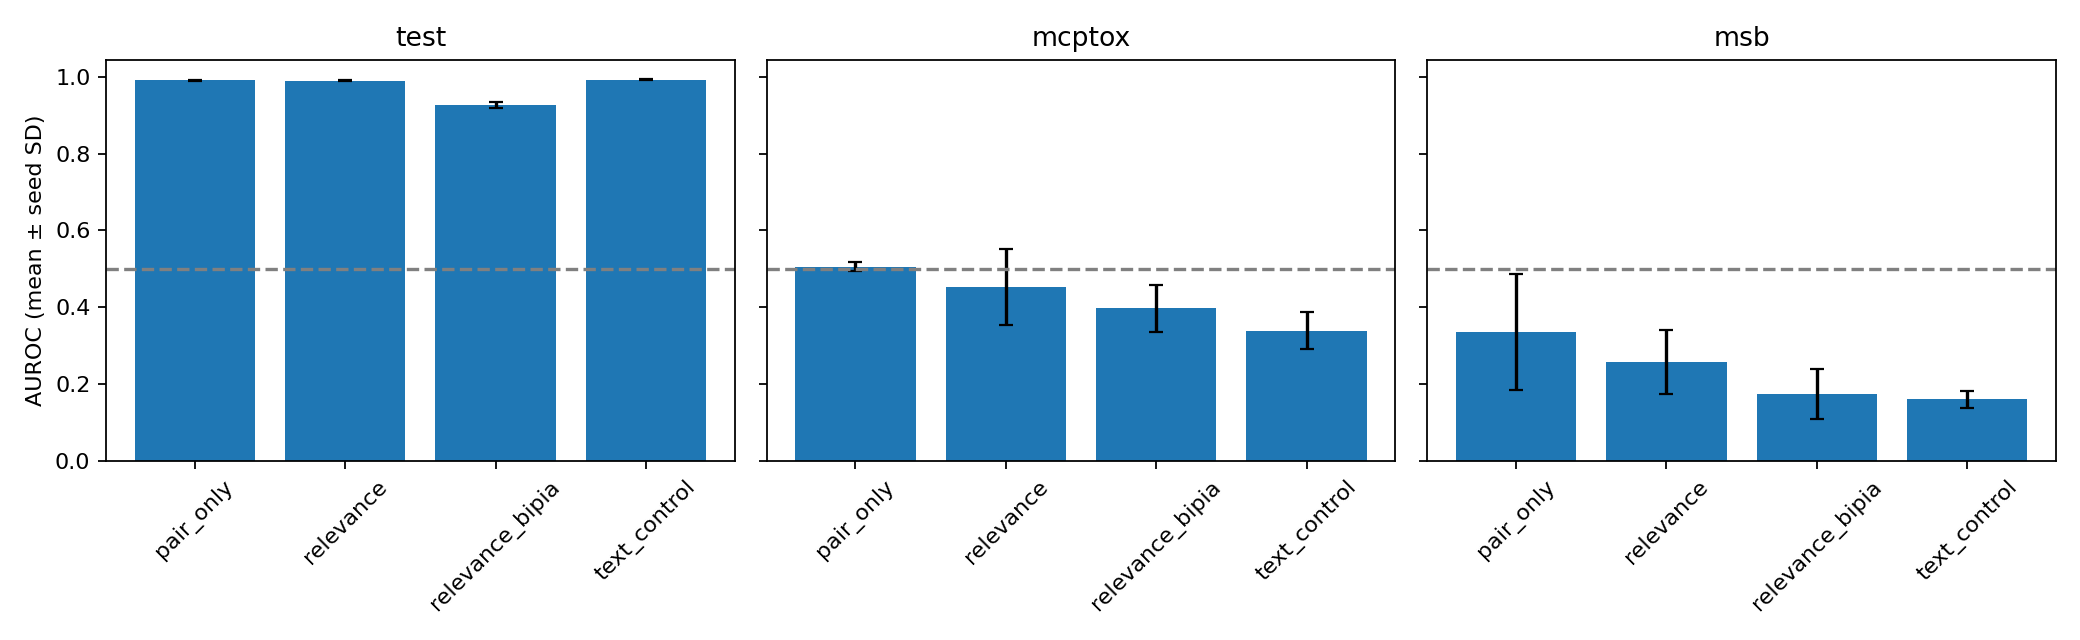

seed                             7267      7268      7269
eval_set metric                                          
mcptox   auroc              -0.098734  0.063345 -0.120652
         tpr_at_matched_fpr -0.096774  0.022333 -0.019851
msb      auroc              -0.011255 -0.062338 -0.158874
         tpr_at_matched_fpr  0.000000 -0.036364 -0.054545
test     auroc              -0.001088 -0.001168 -0.000909
         tpr_at_matched_fpr -0.006590 -0.008237  0.001647

,detector,eval_set,auroc,tpr_at_matched_fpr
0,length_only,test,0.491468,0.077430
7,length_only,mcptox,0.760108,0.002481
8,length_only,msb,0.907359,0.472727


,detector,eval_set,auroc,tpr_at_matched_fpr
0,tfidf,test,0.901576,0.602965
7,tfidf,mcptox,0.700351,0.181141
8,tfidf,msb,0.481385,0.090909


In [ ]:
from IPython.display import Image, Markdown, display
if MODE == "full":
    R = OUT / "reports"
    display(Markdown((R / "summary.md").read_text()), Image(filename=str(R / "auroc.png")))
    effects = pd.read_csv(R / "ablation_deltas.csv")
    display(effects.query("slice == 'all' and comparison == 'pair_only -> relevance' and metric in ['auroc', 'tpr_at_matched_fpr']").pivot_table(
        index=["eval_set", "metric"], columns="seed", values="delta"))
    for name in ("reference_length", "reference_tfidf"):
        display(pd.read_csv(R / (name + ".csv")).query("slice == 'all'")[["detector", "eval_set", "auroc", "tpr_at_matched_fpr"]])
elif MODE == "sweep":
    display(pd.read_csv(OUT / "sweep/trials.csv"))
else:
    smoke = next((OUT / "smoke").glob("*/model/run.json"))
    display(pd.DataFrame(json.loads(smoke.read_text())["history"]))